<a href="https://colab.research.google.com/github/shehin-pixel/aiml/blob/main/Landslide_Prediction_Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import joblib

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:
np.random.seed(42)

n_samples = 1000

rainfall = np.random.uniform(50, 500, n_samples)
slope = np.random.uniform(5, 50, n_samples)
elevation = np.random.uniform(50, 1500, n_samples)
soil_moisture = np.random.uniform(10, 95, n_samples)
temperature = np.random.uniform(15, 35, n_samples)
vegetation_index = np.random.uniform(0.1, 0.9, n_samples)
distance_to_river = np.random.uniform(20, 1000, n_samples)
soil_type = np.random.randint(0, 4, n_samples)

# Create a risk score for generating demonstration labels
risk_score = (
    0.006 * rainfall
    + 0.08 * slope
    + 0.025 * soil_moisture
    - 0.001 * distance_to_river
    - 1.5 * vegetation_index
    + 0.3 * soil_type
    + np.random.normal(0, 1.5, n_samples)
)

# Convert risk score into binary classes
landslide = (risk_score > 2.8).astype(int)

data = pd.DataFrame({
    "rainfall": rainfall,
    "slope": slope,
    "elevation": elevation,
    "soil_moisture": soil_moisture,
    "temperature": temperature,
    "vegetation_index": vegetation_index,
    "distance_to_river": distance_to_river,
    "soil_type": soil_type,
    "landslide": landslide
})

data.head()


,rainfall,slope,elevation,soil_moisture,temperature,vegetation_index,distance_to_river,soil_type,landslide
0,218.543053,13.330982,429.473241,67.179755,26.439918,0.414908,655.291815,2,1
1,477.821438,29.385543,408.119259,77.717919,31.108647,0.478749,188.938635,0,1
2,379.397274,44.282563,1364.069142,31.289771,30.203219,0.783638,874.946672,2,1
3,319.396318,37.950120,411.841990,63.114298,18.077998,0.372004,620.853914,2,1
4,120.208388,41.295252,444.327103,58.598409,17.984989,0.795720,174.059806,0,0


In [ ]:
data.to_csv("landslide_dataset.csv", index=False)

print("Dataset saved successfully!")


Dataset saved successfully!


In [ ]:
df = pd.read_csv("landslide_dataset.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()


Dataset loaded successfully!
Shape: (1000, 9)


,rainfall,slope,elevation,soil_moisture,temperature,vegetation_index,distance_to_river,soil_type,landslide
0,218.543053,13.330982,429.473241,67.179755,26.439918,0.414908,655.291815,2,1
1,477.821438,29.385543,408.119259,77.717919,31.108647,0.478749,188.938635,0,1
2,379.397274,44.282563,1364.069142,31.289771,30.203219,0.783638,874.946672,2,1
3,319.396318,37.950120,411.841990,63.114298,18.077998,0.372004,620.853914,2,1
4,120.208388,41.295252,444.327103,58.598409,17.984989,0.795720,174.059806,0,0


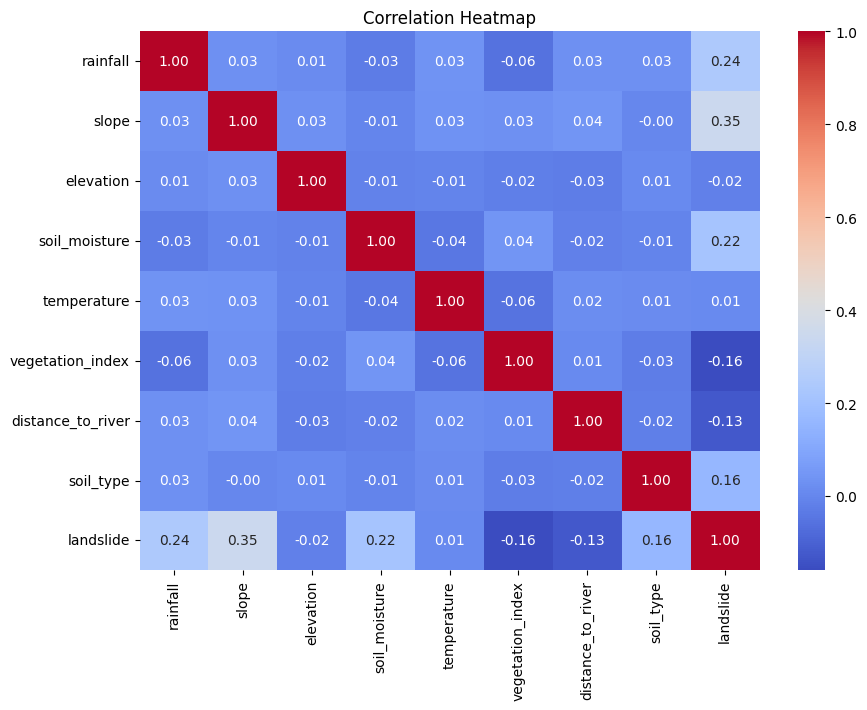

In [ ]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()


In [ ]:
X = df.drop("landslide", axis=1)

y = df["landslide"]

print("Features:")
print(X.columns)

print("\nTarget:")
print(y.name)


Features:
Index(['rainfall', 'slope', 'elevation', 'soil_moisture', 'temperature',
       'vegetation_index', 'distance_to_river', 'soil_type'],
      dtype='object')

Target:
landslide


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 800
Testing samples: 200


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")


Feature scaling completed!


In [ ]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [ ]:
y_pred = model.predict(X_test_scaled)

print(y_pred[:20])


[1 1 1 1 1 0 1 0 1 1 1 1 0 1 1 1 1 1 1 1]


In [ ]:
y_probability = model.predict_proba(X_test_scaled)

print(y_probability[:5])


[[0.02762709 0.97237291]
 [0.1856206  0.8143794 ]
 [0.21618865 0.78381135]
 [0.1738558  0.8261442 ]
 [0.03481905 0.96518095]]


In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)


Accuracy: 0.83
Accuracy (%): 83.0


In [ ]:
precision = precision_score(y_test, y_pred)

print("Precision:", precision)
recall = recall_score(y_test, y_pred)

print("Recall:", recall)


Precision: 0.844311377245509
Recall: 0.9463087248322147


In [ ]:
print("Model Performance")
print("------------------")

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")


Model Performance
------------------
Accuracy  : 0.8300
Precision : 0.8443
Recall    : 0.9463


NameError: name 'f1' is not defined

In [ ]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Landslide", "Landslide"]
))


              precision    recall  f1-score   support

No Landslide       0.76      0.49      0.60        51
   Landslide       0.84      0.95      0.89       149

    accuracy                           0.83       200
   macro avg       0.80      0.72      0.74       200
weighted avg       0.82      0.83      0.82       200



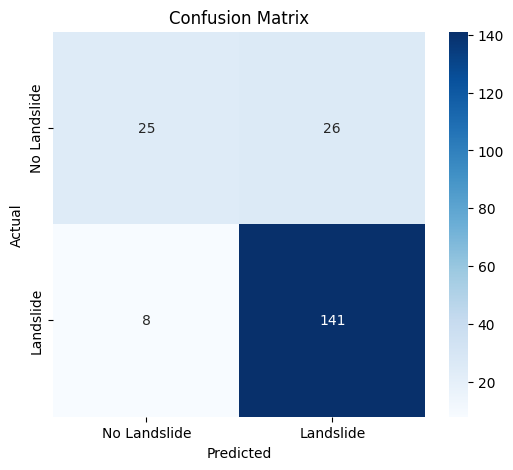

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Landslide", "Landslide"],
    yticklabels=["No Landslide", "Landslide"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()


In [ ]:
joblib.dump(model, "landslide_model.pkl")
joblib.dump(scaler, "landslide_scaler.pkl")

print("Model and scaler saved successfully!")


Model and scaler saved successfully!


In [ ]:
print("===================================")
print("     LANDSLIDE PREDICTION SYSTEM")
print("===================================")

rainfall = float(input("Enter rainfall (mm): "))
slope = float(input("Enter slope (degrees): "))
elevation = float(input("Enter elevation (m): "))
soil_moisture = float(input("Enter soil moisture (%): "))
temperature = float(input("Enter temperature (°C): "))
vegetation_index = float(input("Enter vegetation index: "))
distance_to_river = float(input("Enter distance to river (m): "))
soil_type = int(input("Enter soil type (0-3): "))

user_data = np.array([[
    rainfall,
    slope,
    elevation,
    soil_moisture,
    temperature,
    vegetation_index,
    distance_to_river,
    soil_type
]])

user_data_scaled = scaler.transform(user_data)

prediction = model.predict(user_data_scaled)[0]

probability = model.predict_proba(user_data_scaled)[0][1]

print("\n===================================")

if prediction == 1:
    print("Prediction: LANDSLIDE")
else:
    print("Prediction: NO LANDSLIDE")

print(f"Landslide probability: {probability * 100:.2f}%")

print("===================================")


     LANDSLIDE PREDICTION SYSTEM
Enter rainfall (mm): 12
Enter slope (degrees): 10
Enter elevation (m): 80
Enter soil moisture (%): 24
Enter temperature (°C): 100
Enter vegetation index: 67
Enter distance to river (m): 90
Enter soil type (0-3): 2

Prediction: NO LANDSLIDE
Landslide probability: 0.00%


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
